In [1]:
!pip install torch_geometric -q

In [2]:
import os, warnings
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch_geometric.datasets import QM9
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GCNConv, global_mean_pool
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, WhiteKernel, ConstantKernel
from scipy.stats import norm
warnings.filterwarnings("ignore")

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

from google.colab import drive
drive.mount('/content/drive')
SAVE_PATH = '/content/drive/MyDrive/gnn_qm9.pt'

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Using: cuda
Mounted at /content/drive


In [3]:
dataset = QM9(root='/content/qm9_data')
TARGET_IDX = 4  # HOMO-LUMO gap, in eV

n = len(dataset)
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(n, generator=g)

train_dataset = dataset[perm[:int(0.8 * n)]]
val_dataset   = dataset[perm[int(0.8 * n):int(0.9 * n)]]
test_dataset  = dataset[perm[int(0.9 * n):]]
print(f"train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=256)
test_loader  = DataLoader(test_dataset, batch_size=256)

train_mean = train_dataset.y[:, TARGET_IDX].mean().item()
baseline_mae = (val_dataset.y[:, TARGET_IDX] - train_mean).abs().mean().item()
print("Baseline MAE (always predict mean):", round(baseline_mae, 3))

Extracting /content/qm9_data/raw/qm9_v3.zip
Processing...
Using a pre-processed version of the dataset. Please install 'rdkit' to alternatively process the raw data.
Done!


train: 104664, val: 13083, test: 13084
Baseline MAE (always predict mean): 1.082


In [4]:
class GNN(nn.Module):
    def __init__(self, num_node_features, hidden_dim=64):
        super().__init__()
        self.conv1 = GCNConv(num_node_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, hidden_dim)
        self.conv3 = GCNConv(hidden_dim, hidden_dim)
        self.linear = nn.Linear(hidden_dim, 1)

    def embed(self, x, edge_index, batch):
        x = self.conv1(x, edge_index).relu()
        x = self.conv2(x, edge_index).relu()
        x = self.conv3(x, edge_index).relu()
        return global_mean_pool(x, batch)   # 64-number summary per molecule

    def forward(self, x, edge_index, batch):
        return self.linear(self.embed(x, edge_index, batch))

model = GNN(dataset.num_node_features).to(device)

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.L1Loss()

def evaluate(loader):
    model.eval()
    total = 0
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            pred = model(batch.x, batch.edge_index, batch.batch).squeeze()
            total += (pred - batch.y[:, TARGET_IDX]).abs().sum().item()
    return total / len(loader.dataset)

if os.path.exists(SAVE_PATH):
    model.load_state_dict(torch.load(SAVE_PATH, map_location=device))
    print("Loaded saved model from Drive")
else:
    for epoch in range(30):
        model.train()
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            pred = model(batch.x, batch.edge_index, batch.batch).squeeze()
            loss = loss_fn(pred, batch.y[:, TARGET_IDX])
            loss.backward()
            optimizer.step()
        print(f"epoch {epoch}: val MAE {evaluate(val_loader):.4f}")
    torch.save(model.state_dict(), SAVE_PATH)
    print("Saved model to Drive")

print("Test MAE:", round(evaluate(test_loader), 3), "eV")

epoch 0: val MAE 0.8352
epoch 1: val MAE 0.7752
epoch 2: val MAE 0.7525
epoch 3: val MAE 0.7356
epoch 4: val MAE 0.7253
epoch 5: val MAE 0.6809
epoch 6: val MAE 0.6490
epoch 7: val MAE 0.6361
epoch 8: val MAE 0.6189
epoch 9: val MAE 0.5942
epoch 10: val MAE 0.5739
epoch 11: val MAE 0.5667
epoch 12: val MAE 0.5704
epoch 13: val MAE 0.5644
epoch 14: val MAE 0.5765
epoch 15: val MAE 0.5478
epoch 16: val MAE 0.5492
epoch 17: val MAE 0.5622
epoch 18: val MAE 0.5345
epoch 19: val MAE 0.5216
epoch 20: val MAE 0.5175
epoch 21: val MAE 0.4978
epoch 22: val MAE 0.4951
epoch 23: val MAE 0.4897
epoch 24: val MAE 0.4863
epoch 25: val MAE 0.4781
epoch 26: val MAE 0.4756
epoch 27: val MAE 0.4716
epoch 28: val MAE 0.5063
epoch 29: val MAE 0.5333
Saved model to Drive
Test MAE: 0.539 eV


In [6]:
POOL_SIZE = 5000
rng = np.random.default_rng(SEED)
pool_idx = torch.tensor(rng.choice(len(test_dataset), POOL_SIZE, replace=False))
pool_loader = DataLoader(test_dataset[pool_idx], batch_size=256)

model.eval()
embs, gaps = [], []
with torch.no_grad():
    for batch in pool_loader:
        batch = batch.to(device)
        embs.append(model.embed(batch.x, batch.edge_index, batch.batch).cpu())
        gaps.append(batch.y[:, TARGET_IDX].cpu())

X = torch.cat(embs).numpy()
y = torch.cat(gaps).numpy()

X = StandardScaler().fit_transform(X)
X = PCA(n_components=10, random_state=SEED).fit_transform(X)

top1_threshold = np.percentile(y, 1)
print("Pool size:", len(y))
print("Smallest gap in pool:", round(y.min(), 3), "eV")
print("Top-1% threshold:", round(top1_threshold, 3), "eV")

Pool size: 5000
Smallest gap in pool: 2.259 eV
Top-1% threshold: 4.114 eV


In [7]:
def expected_improvement(mu, sigma, best, xi=0.01):
    # we want SMALL gaps, so improvement = how far below the current best
    imp = best - mu - xi
    Z = imp / (sigma + 1e-9)
    ei = imp * norm.cdf(Z) + sigma * norm.pdf(Z)
    ei[sigma < 1e-9] = 0
    return ei

def run_bo(seed, n_init=20, n_rounds=150):
    rng = np.random.default_rng(seed)
    revealed = list(rng.choice(len(y), n_init, replace=False))
    history = [y[revealed].min()]
    kernel = ConstantKernel(1.0) * Matern(length_scale=1.0, nu=2.5) + WhiteKernel(1e-3)
    for _ in range(n_rounds):
        gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, random_state=seed)
        gp.fit(X[revealed], y[revealed])
        mask = np.ones(len(y), dtype=bool)
        mask[revealed] = False
        candidates = np.where(mask)[0]
        mu, sigma = gp.predict(X[candidates], return_std=True)
        ei = expected_improvement(mu, sigma, y[revealed].min())
        revealed.append(candidates[np.argmax(ei)])
        history.append(y[revealed].min())
    return np.array(history)

def run_random(seed, n_init=20, n_rounds=150):
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(y))[: n_init + n_rounds]  # same first 20 as BO
    return np.array([y[order[: n_init + k]].min() for k in range(n_rounds + 1)])

SEEDS = [0, 1, 2, 3, 4]
bo_runs, rand_runs = [], []
for s in SEEDS:
    bo_runs.append(run_bo(s))
    rand_runs.append(run_random(s))
    print(f"seed {s}: BO best {bo_runs[-1][-1]:.3f} eV | random best {rand_runs[-1][-1]:.3f} eV")

bo_runs, rand_runs = np.array(bo_runs), np.array(rand_runs)

seed 0: BO best 2.259 eV | random best 3.853 eV
seed 1: BO best 2.259 eV | random best 4.438 eV
seed 2: BO best 2.259 eV | random best 3.589 eV
seed 3: BO best 2.259 eV | random best 2.887 eV
seed 4: BO best 2.259 eV | random best 3.483 eV


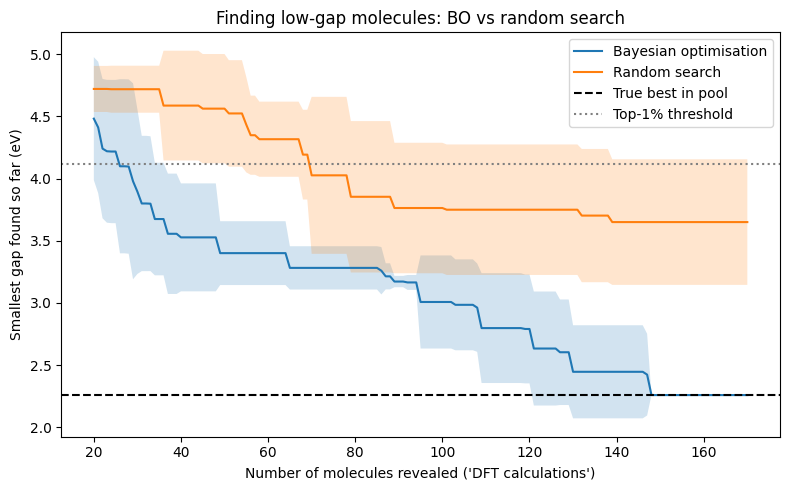

In [8]:
x_axis = np.arange(20, 20 + bo_runs.shape[1])
plt.figure(figsize=(8, 5))
for runs, label in [(bo_runs, "Bayesian optimisation"), (rand_runs, "Random search")]:
    m, s = runs.mean(0), runs.std(0)
    plt.plot(x_axis, m, label=label)
    plt.fill_between(x_axis, m - s, m + s, alpha=0.2)
plt.axhline(y.min(), color="k", ls="--", label="True best in pool")
plt.axhline(top1_threshold, color="grey", ls=":", label="Top-1% threshold")
plt.xlabel("Number of molecules revealed ('DFT calculations')")
plt.ylabel("Smallest gap found so far (eV)")
plt.title("Finding low-gap molecules: BO vs random search")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
def reveals_to_top1(runs):
    hits = []
    for h in runs:
        idx = np.where(h <= top1_threshold)[0]
        hits.append(20 + idx[0] if len(idx) else np.nan)
    return np.array(hits)

bo_hits, rand_hits = reveals_to_top1(bo_runs), reveals_to_top1(rand_runs)
print("Reveals needed to find a top-1% molecule (out of 5,000):")
print("  BO:    ", bo_hits, "-> average", np.nanmean(bo_hits))
print("  Random:", rand_hits, "-> average", np.nanmean(rand_hits))

Reveals needed to find a top-1% molecule (out of 5,000):
  BO:     [20 34 22 49 20] -> average 29.0
  Random: [139.  nan  79.  36.  68.] -> average 80.5
